# Mursaleen BSCS-7D DLP Assignment 2, Section B: Robust CIFAR-10 Classification Under Distribution Shift

##

In [ ]:
import os
import time
import json
import math
import random
import copy
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.transforms import v2 as T
import torchvision.transforms.functional as TF
from sklearn.metrics import confusion_matrix
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", 120)
SEEDS = [0, 1, 2]
DATA_SEED = 42
SHIFT_SEED = 2026
MAX_EPOCHS = 60
BATCH_SIZE = 32
DATA_ROOT = "data"
PROVIDED_DIR = "provided"
os.makedirs("checkpoints", exist_ok=True)
os.makedirs("results", exist_ok=True)
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(0)
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | device: {DEVICE}")
print(f"seeds used for training: {SEEDS} | data seed: {DATA_SEED} | shift seed: {SHIFT_SEED}")

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | device: cuda
seeds used for training: [0, 1, 2] | data seed: 42 | shift seed: 2026


## 1. Data
### 1.1 Load CIFAR-10

In [ ]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
MEAN = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
STD = torch.tensor([0.247, 0.2435, 0.2616]).view(3, 1, 1)
def load_cifar10(root=DATA_ROOT):
    cache = os.path.join(root, "cifar10_uint8.npz")
    if os.path.exists(cache):
        d = np.load(cache)
        return (d["xtr"], d["ytr"], d["xte"], d["yte"], str(d["src"]))
    folder = os.path.join(root, "CIFAR-10-images")
    if os.path.isdir(folder):
        from PIL import Image
        def read_split(split):
            xs = []
            ys = []
            for ci, c in enumerate(CLASSES):
                d = os.path.join(folder, split, c)
                for f in sorted(os.listdir(d)):
                    xs.append(np.array(Image.open(os.path.join(d, f)).convert("RGB")))
                    ys.append(ci)
            return (np.stack(xs).astype(np.uint8), np.array(ys, dtype=np.int64))

        xtr, ytr = read_split("train")
        xte, yte = read_split("test")
        src = "local image-folder copy of CIFAR-10"
    else:
        tr = torchvision.datasets.CIFAR10(root, train=True, download=True)
        te = torchvision.datasets.CIFAR10(root, train=False, download=True)
        xtr = tr.data
        ytr = np.array(tr.targets, dtype=np.int64)
        xte = te.data
        yte = np.array(te.targets, dtype=np.int64)
        src = "torchvision.datasets.CIFAR10"
    os.makedirs(root, exist_ok=True)
    np.savez_compressed(cache, xtr=xtr, ytr=ytr, xte=xte, yte=yte, src=src)
    return (xtr, ytr, xte, yte, src)
x_train_full, y_train_full, x_clean_test, y_clean_test, data_source = load_cifar10()
print(f"source: {data_source}")
print(
    f"full train: {x_train_full.shape}, clean test: {x_clean_test.shape}, dtype {x_train_full.dtype}"
)

source: torchvision.datasets.CIFAR10
full train: (50000, 32, 32, 3), clean test: (10000, 32, 32, 3), dtype uint8


### 1.2 train_small and 400 / 100 split

In [ ]:
provided_small = os.path.join(PROVIDED_DIR, "train_small.npz")
if os.path.exists(provided_small):
    d = np.load(provided_small)
    x_small = d["x"].astype(np.uint8)
    y_small = d["y"].astype(np.int64)
    print("using instructor-provided train_small")
else:
    rng = np.random.default_rng(DATA_SEED)
    idx_small = np.concatenate(
        [rng.choice(np.where(y_train_full == c)[0], 50, replace=False) for c in range(10)]
    )
    x_small = x_train_full[idx_small]
    y_small = y_train_full[idx_small]
    print(f"train_small drawn with DATA_SEED={DATA_SEED}")
rng = np.random.default_rng(DATA_SEED)
tr_idx = []
va_idx = []
for c in range(10):
    ids = rng.permutation(np.where(y_small == c)[0])
    tr_idx += list(ids[:40])
    va_idx += list(ids[40:])
tr_idx = np.array(sorted(tr_idx))
va_idx = np.array(sorted(va_idx))
x_tr = x_small[tr_idx]
y_tr = y_small[tr_idx]
x_va = x_small[va_idx]
y_va = y_small[va_idx]
print(f"train: {x_tr.shape} {np.bincount(y_tr)}")
print(f"val:   {x_va.shape} {np.bincount(y_va)}")

train_small drawn with DATA_SEED=42
train: (400, 32, 32, 3) [40 40 40 40 40 40 40 40 40 40]
val:   (100, 32, 32, 3) [10 10 10 10 10 10 10 10 10 10]


### 1.3 Shifted test set
Simulated substitute (no official file used): rotation ±25°, brightness/contrast, blur, noise, occlusion and a hidden channel swap.

In [ ]:
def channel_swap(x, rng):
    perms = [(0, 2, 1), (1, 0, 2), (1, 2, 0), (2, 0, 1), (2, 1, 0)]
    return x[list(perms[rng.integers(len(perms))])]
def shift_corrupt(img, rng, hidden_log=None):
    x = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0
    x = TF.rotate(
        x, float(rng.uniform(-25, 25)), interpolation=T.InterpolationMode.BILINEAR, fill=0.0
    )
    b = rng.uniform(0.5, 1.5)
    c = rng.uniform(0.6, 1.4)
    x = x * b
    m = x.mean()
    x = (x - m) * c + m
    if rng.random() < 0.3:
        x = TF.gaussian_blur(x, kernel_size=3, sigma=float(rng.uniform(0.6, 1.2)))
    if rng.random() < 0.3:
        x = x + torch.from_numpy(rng.normal(0, rng.uniform(0.03, 0.08), x.shape)).float()
    x = x.clamp(0, 1)
    if rng.random() < 0.6:
        h = int(rng.integers(12, 21))
        w = int(round(256 / h))
        y0 = int(rng.integers(0, 33 - h))
        x0 = int(rng.integers(0, 33 - w))
        x[:, y0 : y0 + h, x0 : x0 + w] = float(rng.uniform(0, 1))
    hidden = rng.random() < 0.5
    if hidden:
        x = channel_swap(x, rng)
    if hidden_log is not None:
        hidden_log.append(bool(hidden))
    return (x * 255).round().byte().permute(1, 2, 0).numpy()
provided_shift = os.path.join(PROVIDED_DIR, "shifted_test.npz")
if os.path.exists(provided_shift):
    d = np.load(provided_shift)
    x_shift = d["x"].astype(np.uint8)
    y_shift = d["y"].astype(np.int64)
    shift_hidden_mask = None
    print("using instructor-provided shifted_test")
else:
    rng = np.random.default_rng(SHIFT_SEED)
    hidden_log = []
    x_shift = np.stack([shift_corrupt(im, rng, hidden_log) for im in x_clean_test])
    y_shift = y_clean_test.copy()
    shift_hidden_mask = np.array(hidden_log)
    print(
        f"stand-in shifted_test built with SHIFT_SEED={SHIFT_SEED} ({shift_hidden_mask.mean():.1%} of images also received the hidden corruption)"
    )
rng = np.random.default_rng(SHIFT_SEED + 1)
x_hidden = np.stack(
    [
        channel_swap(torch.from_numpy(im).permute(2, 0, 1), rng).permute(1, 2, 0).numpy()
        for im in x_clean_test
    ]
)
print(f"shifted_test: {x_shift.shape}, hidden-only test: {x_hidden.shape}")

stand-in shifted_test built with SHIFT_SEED=2026 (49.5% of images also received the hidden corruption)
shifted_test: (10000, 32, 32, 3), hidden-only test: (10000, 32, 32, 3)


### 1.4 Shifted validation split
Corrupted copies of the 100 validation images, used only for model selection.

In [ ]:
def listed_corrupt(img, rng):
    x = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0
    x = TF.rotate(
        x, float(rng.uniform(-25, 25)), interpolation=T.InterpolationMode.BILINEAR, fill=0.0
    )
    x = TF.adjust_brightness(x, float(rng.uniform(0.6, 1.4)))
    x = TF.adjust_contrast(x, float(rng.uniform(0.7, 1.3)))
    if rng.random() < 0.3:
        x = TF.gaussian_blur(x, kernel_size=3, sigma=float(rng.uniform(0.5, 1.0)))
    if rng.random() < 0.3:
        x = (x + torch.from_numpy(rng.normal(0, 0.05, x.shape)).float()).clamp(0, 1)
    if rng.random() < 0.5:
        y0 = int(rng.integers(0, 17))
        x0 = int(rng.integers(0, 17))
        x[:, y0 : y0 + 16, x0 : x0 + 16] = 0.5
    return (x.clamp(0, 1) * 255).round().byte().permute(1, 2, 0).numpy()
rng = np.random.default_rng(DATA_SEED + 7)
x_vs = np.stack([listed_corrupt(im, rng) for _ in range(3) for im in x_va])
y_vs = np.tile(y_va, 3)
x_vr = np.concatenate([x_va, x_vs])
y_vr = np.concatenate([y_va, y_vs])
print(f"shifted validation: {x_vs.shape}, robust validation (clean + shifted): {x_vr.shape}")

shifted validation: (300, 32, 32, 3), robust validation (clean + shifted): (400, 32, 32, 3)


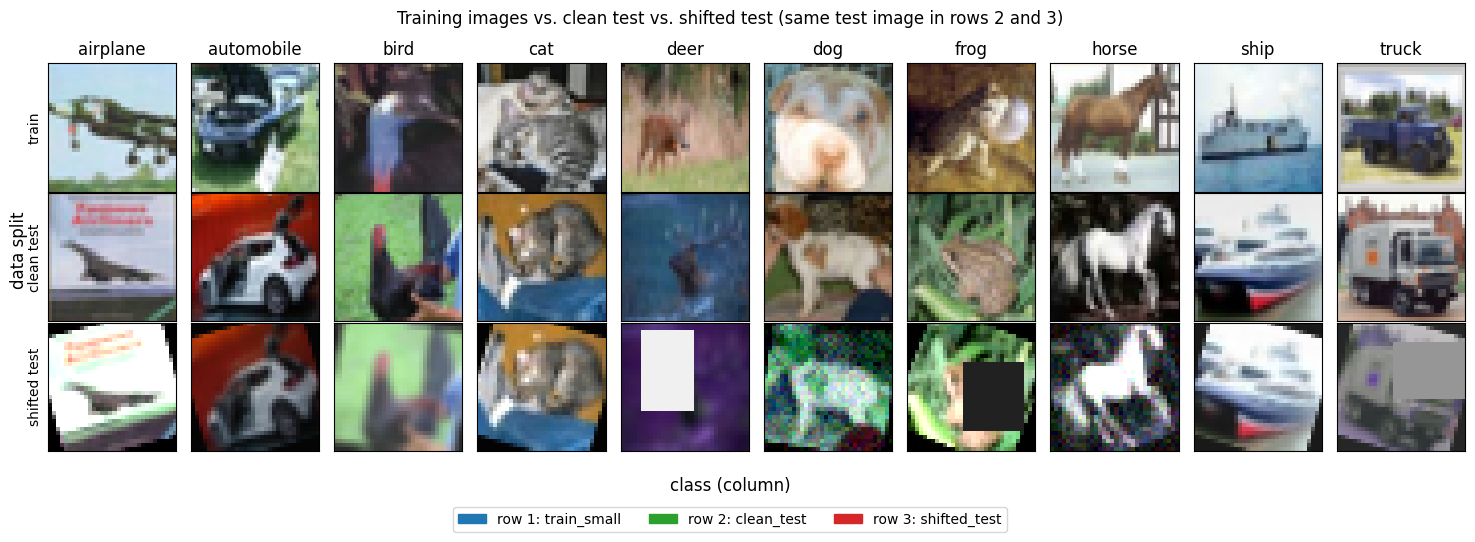

In [ ]:
fig, axes = plt.subplots(3, 10, figsize=(15, 5))
for c in range(10):
    i = np.where(y_clean_test == c)[0][0]
    for r, (arr, name) in enumerate(
        [
            (x_tr[np.where(y_tr == c)[0][0]], "train"),
            (x_clean_test[i], "clean test"),
            (x_shift[i], "shifted test"),
        ]
    ):
        axes[r, c].imshow(arr)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
        if c == 0:
            axes[r, c].set_ylabel(name)
    axes[0, c].set_title(CLASSES[c])
fig.suptitle("Training images vs. clean test vs. shifted test (same test image in rows 2 and 3)")
fig.supxlabel("class (column)")
fig.supylabel("data split")
fig.legend(
    handles=[
        Patch(color="tab:blue", label="row 1: train_small"),
        Patch(color="tab:green", label="row 2: clean_test"),
        Patch(color="tab:red", label="row 3: shifted_test"),
    ],
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.0),
)
plt.tight_layout()
plt.show()

## 2. Model: MiniInceptionNet
Stem conv → 4 Inception blocks (1×1, 3×3, 5×5 and pool branches) → Global Average Pooling → Dropout → Linear.

In [ ]:
class ConvBNReLU(nn.Sequential):

    def __init__(self, cin, cout, k, stride=1):
        super().__init__(
            nn.Conv2d(cin, cout, k, stride, k // 2, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True),
        )
class InceptionBlock(nn.Module):
    def __init__(self, cin, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        self.b1 = ConvBNReLU(cin, c1, 1)
        self.b3 = nn.Sequential(ConvBNReLU(cin, c3r, 1), ConvBNReLU(c3r, c3, 3))
        self.b5 = nn.Sequential(ConvBNReLU(cin, c5r, 1), ConvBNReLU(c5r, c5, 5))
        self.bp = nn.Sequential(nn.MaxPool2d(3, 1, 1), ConvBNReLU(cin, cp, 1))
        self.out_channels = c1 + c3 + c5 + cp
    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], dim=1)
class MiniInceptionNet(nn.Module):
    def __init__(self, num_classes=10, dropout=0.3):
        super().__init__()
        self.stem = nn.Sequential(ConvBNReLU(3, 32, 3), nn.MaxPool2d(2), ConvBNReLU(32, 64, 3))
        self.inc3a = InceptionBlock(64, 32, 48, 64, 8, 16, 16)
        self.pool3 = nn.MaxPool2d(2)
        self.inc4a = InceptionBlock(128, 48, 64, 96, 16, 32, 32)
        self.inc4b = InceptionBlock(208, 96, 64, 128, 16, 32, 32)
        self.pool4 = nn.MaxPool2d(2)
        self.inc5a = InceptionBlock(288, 128, 96, 192, 24, 48, 64)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(self.inc5a.out_channels, num_classes)
    def forward(self, x):
        x = self.stem(x)
        x = self.pool3(self.inc3a(x))
        x = self.pool4(self.inc4b(self.inc4a(x)))
        x = self.inc5a(x)
        x = torch.flatten(self.gap(x), 1)
        return self.fc(self.drop(x))
def count_params(m):
    return sum((p.numel() for p in m.parameters() if p.requires_grad))
_m = MiniInceptionNet()
N_PARAMS = count_params(_m)
print(f"trainable parameters: {N_PARAMS:,}")
assert N_PARAMS <= 1000000, "model exceeds the 1M-parameter limit"
for name, mod in _m.named_children():
    n = count_params(mod)
    if n:
        print(f"  {name:6s} {n:>9,}")
del _m

trainable parameters: 567,018
  stem      19,488
  inc3a     37,872
  inc4a     89,152
  inc4b    130,528
  inc5a    285,648
  fc         4,330


## 3. Training utilities
### 3.1 On-the-fly augmentation

In [ ]:
class RandomGaussianNoise(nn.Module):
    def __init__(self, p=0.3, max_std=0.08):
        super().__init__()
        self.p, self.max_std = (p, max_std)
    def forward(self, x):
        if torch.rand(1).item() < self.p:
            std = torch.empty(1).uniform_(0.01, self.max_std).item()
            x = (x + torch.randn_like(x) * std).clamp(0, 1)
        return x
def build_transform(aug):
    t = []
    if "geo" in aug:
        t += [
            T.RandomCrop(32, padding=4, padding_mode="reflect"),
            T.RandomHorizontalFlip(),
            T.RandomAffine(degrees=30, translate=(0.05, 0.05), scale=(0.9, 1.1)),
        ]
    if "photo" in aug:
        t += [
            T.ColorJitter(brightness=0.5, contrast=0.4, saturation=0.4, hue=0.05),
            T.RandomGrayscale(p=0.1),
            T.RandomApply([T.GaussianBlur(3, sigma=(0.1, 1.5))], p=0.3),
        ]
    t += [T.ToDtype(torch.float32, scale=True)]
    if "photo" in aug:
        t += [RandomGaussianNoise(p=0.3, max_std=0.08)]
    t += [T.Normalize(MEAN.flatten().tolist(), STD.flatten().tolist())]
    if "erase" in aug:
        t += [T.RandomErasing(p=0.5, scale=(0.05, 0.3), ratio=(0.5, 2.0), value=0)]
    return T.Compose(t)
class AugDataset(torch.utils.data.Dataset):
    def __init__(self, x, y, transform):
        self.x = torch.from_numpy(x).permute(0, 3, 1, 2).contiguous()
        self.y = torch.from_numpy(y)
        self.transform = transform
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return (self.transform(self.x[i]), self.y[i])
def to_input(x_uint8):
    x = torch.from_numpy(x_uint8).permute(0, 3, 1, 2).float() / 255.0
    return (x - MEAN) / STD

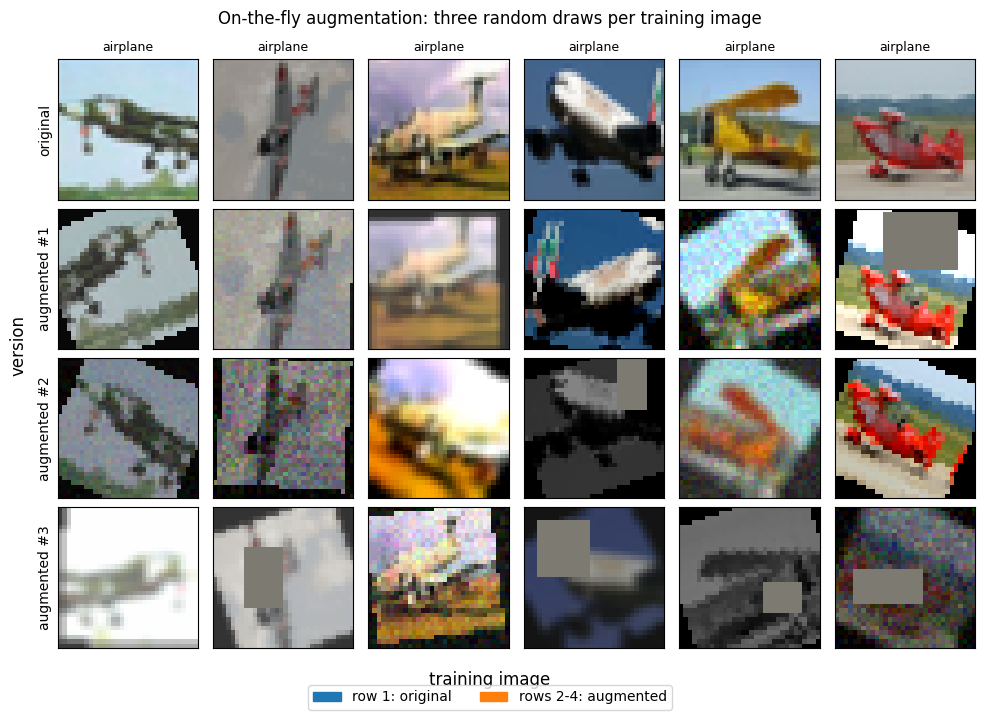

In [ ]:
_t = build_transform(["geo", "photo", "erase"])
_x = torch.from_numpy(x_tr[:6]).permute(0, 3, 1, 2)
set_seed(0)
fig, axes = plt.subplots(4, 6, figsize=(10, 7))
for j in range(6):
    axes[0, j].imshow(x_tr[j])
    axes[0, j].set_title(CLASSES[y_tr[j]], fontsize=9)
    for r in range(1, 4):
        a = (_t(_x[j]) * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()
        axes[r, j].imshow(a)
    for r in range(4):
        axes[r, j].set_xticks([])
        axes[r, j].set_yticks([])
axes[0, 0].set_ylabel("original")
for r in range(1, 4):
    axes[r, 0].set_ylabel(f"augmented #{r}")
fig.suptitle("On-the-fly augmentation: three random draws per training image")
fig.supxlabel("training image")
fig.supylabel("version")
fig.legend(
    handles=[
        Patch(color="tab:blue", label="row 1: original"),
        Patch(color="tab:orange", label="rows 2-4: augmented"),
    ],
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.03),
)
plt.tight_layout()
plt.show()
del _t, _x

### 3.2 Training loop and evaluation

In [ ]:
def mix_batch(x, y):
    perm = torch.randperm(x.size(0))
    if torch.rand(1).item() < 0.5:
        lam = torch.distributions.Beta(0.2, 0.2).sample().item()
        x = lam * x + (1 - lam) * x[perm]
    else:
        lam = torch.distributions.Beta(1.0, 1.0).sample().item()
        H, W = x.shape[2:]
        rh = int(H * math.sqrt(1 - lam))
        rw = int(W * math.sqrt(1 - lam))
        cy = torch.randint(H, (1,)).item()
        cx = torch.randint(W, (1,)).item()
        y0 = max(cy - rh // 2, 0)
        y1 = min(cy + rh // 2, H)
        x0 = max(cx - rw // 2, 0)
        x1 = min(cx + rw // 2, W)
        x = x.clone()
        x[:, :, y0:y1, x0:x1] = x[perm][:, :, y0:y1, x0:x1]
        lam = 1 - (y1 - y0) * (x1 - x0) / (H * W)
    return (x, y, y[perm], lam)
@torch.no_grad()
def predict_probs(model, x_uint8, bs=1000):
    model.eval()
    out = []
    for i in range(0, len(x_uint8), bs):
        xb = to_input(x_uint8[i : i + bs]).to(DEVICE)
        out.append(F.softmax(model(xb), dim=1).cpu())
    return torch.cat(out).numpy()
@torch.no_grad()
def evaluate(model, x_uint8, y, criterion=None):
    p = predict_probs(model, x_uint8)
    acc = float((p.argmax(1) == y).mean())
    loss = (
        float(F.nll_loss(torch.log(torch.from_numpy(p) + 1e-12), torch.from_numpy(y)))
        if criterion
        else None
    )
    return (acc, loss)
def param_groups(model, wd):
    decay = []
    no_decay = []
    for n, p in model.named_parameters():
        (no_decay if p.ndim <= 1 else decay).append(p)
    return [{"params": decay, "weight_decay": wd}, {"params": no_decay, "weight_decay": 0.0}]
def train_model(cfg, seed, epochs=MAX_EPOCHS, log_every=0):
    set_seed(seed)
    model = MiniInceptionNet(dropout=cfg["dropout"]).to(DEVICE)
    ds = AugDataset(x_tr, y_tr, build_transform(cfg["aug"]))
    g = torch.Generator().manual_seed(seed)
    loader = torch.utils.data.DataLoader(
        ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, generator=g, num_workers=0
    )
    opt = torch.optim.SGD(param_groups(model, cfg["wd"]), lr=cfg["lr"], momentum=0.9, nesterov=True)
    steps = epochs * len(loader)
    warm = 3 * len(loader)
    if cfg["sched"] == "cosine":
        lr_fn = lambda s: (
            (s + 1) / warm
            if s < warm
            else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(steps - warm, 1)))
        )
    else:
        lr_fn = lambda s: 1.0
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_fn)
    crit = nn.CrossEntropyLoss(label_smoothing=cfg["ls"])
    ema = (
        torch.optim.swa_utils.AveragedModel(
            model,
            multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(cfg["ema"]),
            use_buffers=True,
        )
        if cfg.get("ema")
        else None
    )
    hist = {
        k: []
        for k in [
            "train_loss",
            "train_acc",
            "val_loss",
            "val_acc",
            "vshift_loss",
            "vshift_acc",
            "vrob_acc",
            "vrob_loss",
        ]
    }
    best = (-1.0, float("inf"))
    best_state = None
    best_ep = 0
    since_best = 0
    for ep in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            if cfg["mix"]:
                xb, ya, yb2, lam = mix_batch(xb, yb)
                out = model(xb)
                loss = lam * crit(out, ya) + (1 - lam) * crit(out, yb2)
            else:
                loss = crit(model(xb), yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            if ema is not None:
                ema.update_parameters(model)
        eval_model = ema.module if ema is not None else model
        tr_acc, tr_loss = evaluate(eval_model, x_tr, y_tr, crit)
        pv = predict_probs(eval_model, x_vr)
        ok = pv.argmax(1) == y_vr
        nll = -np.log(pv[np.arange(len(y_vr)), y_vr] + 1e-12)
        va_acc = ok[:100].mean()
        va_loss = nll[:100].mean()
        vs_acc = ok[100:].mean()
        vs_loss = nll[100:].mean()
        vr_acc = ok.mean()
        vr_loss = nll.mean()
        for k, v in zip(hist, [tr_loss, tr_acc, va_loss, va_acc, vs_loss, vs_acc, vr_acc, vr_loss]):
            hist[k].append(float(v))
        if log_every and ep % log_every == 0:
            print(
                f"  ep {ep:2d}  train {tr_acc:.3f}  val {va_acc:.3f}  shifted-val {vs_acc:.3f}  robust-val {vr_acc:.3f}"
            )
        if cfg["select_best"] and (vr_acc > best[0] or (vr_acc == best[0] and vr_loss < best[1])):
            best = (vr_acc, vr_loss)
            best_ep = ep
            since_best = 0
            best_state = copy.deepcopy(eval_model.state_dict())
        else:
            since_best += 1
        if cfg["patience"] and since_best >= cfg["patience"]:
            break
    final_model = MiniInceptionNet(dropout=cfg["dropout"]).to(DEVICE)
    final_model.load_state_dict(best_state if cfg["select_best"] else eval_model.state_dict())
    return (final_model, hist, best_ep if cfg["select_best"] else len(hist["val_acc"]))
RESULTS = {}
def slug(name):
    return "".join((ch if ch.isalnum() else "_" for ch in name)).strip("_")
def run_config(name, cfg, seeds=SEEDS):
    rows = []
    hists = []
    t0 = time.time()
    for s in seeds:
        model, hist, best_ep = train_model(cfg, s)
        r = {
            "seed": s,
            "best_epoch": best_ep,
            "epochs_run": len(hist["val_acc"]),
            "train_acc": evaluate(model, x_tr, y_tr)[0],
            "val_acc": evaluate(model, x_va, y_va)[0],
            "val_shift_acc": evaluate(model, x_vs, y_vs)[0],
            "val_robust_acc": evaluate(model, x_vr, y_vr)[0],
            "clean_test": evaluate(model, x_clean_test, y_clean_test)[0],
            "shifted_test": evaluate(model, x_shift, y_shift)[0],
        }
        rows.append(r)
        hists.append(hist)
        torch.save(model.state_dict(), f"checkpoints/{slug(name)}_seed{s}.pt")
    df = pd.DataFrame(rows)
    RESULTS[name] = {"cfg": cfg, "rows": rows, "hists": hists}
    with open(f"results/{slug(name)}.json", "w") as f:
        json.dump({"cfg": cfg, "rows": rows, "hists": hists}, f, indent=1)
    m = df.mean(numeric_only=True)
    sd = df.std(numeric_only=True, ddof=0)
    print(
        f"[{name}] {time.time() - t0:.0f}s | "
        + " | ".join(
            (
                f"{k} {100 * m[k]:.1f}±{100 * sd[k]:.1f}"
                for k in ["train_acc", "val_acc", "val_shift_acc", "clean_test", "shifted_test"]
            )
        )
    )
    return df
def pm(df, col):
    return f"{100 * df[col].mean():.1f} ± {100 * df[col].std(ddof=0):.1f}"
def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for key, a, ylab in [("acc", ax[0], "accuracy"), ("loss", ax[1], "cross-entropy loss")]:
        for split, col in [("train", "tab:blue"), ("val", "tab:orange"), ("vshift", "tab:red")]:
            arr = [h[f"{split}_{key}"] for h in hists]
            split = {"train": "train (clean)", "val": "val (clean)", "vshift": "shifted val"}[split]
            L = min((len(a_) for a_ in arr))
            arr = np.array([a_[:L] for a_ in arr])
            ep = np.arange(1, L + 1)
            a.plot(ep, arr.mean(0), color=col, label=f"{split} (mean of {len(arr)} seeds)")
            a.fill_between(
                ep,
                arr.mean(0) - arr.std(0),
                arr.mean(0) + arr.std(0),
                color=col,
                alpha=0.2,
                label=f"{split} ± 1 std",
            )
        a.set_xlabel("epoch")
        a.set_ylabel(ylab)
        a.set_title(f"{title}: {ylab}")
        a.legend()
        a.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## Part A: Baseline (no augmentation)

In [ ]:
BASELINE_CFG = dict(
    aug=[],
    dropout=0.0,
    wd=0.0,
    lr=0.05,
    sched="constant",
    ls=0.0,
    mix=False,
    select_best=False,
    patience=None,
    ema=None,
)
df_base = run_config("Part A baseline", BASELINE_CFG)
df_base

[Part A baseline] 46s | train_acc 100.0±0.0 | val_acc 47.0±4.5 | val_shift_acc 23.6±1.6 | clean_test 43.1±0.5 | shifted_test 20.5±0.3


,seed,best_epoch,epochs_run,train_acc,val_acc,val_shift_acc,val_robust_acc,clean_test,shifted_test
0,0,60,60,1.0,0.41,0.243333,0.2850,0.4357,0.2069
1,1,60,60,1.0,0.48,0.213333,0.2800,0.4243,0.2065
2,2,60,60,1.0,0.52,0.250000,0.3175,0.4332,0.2010


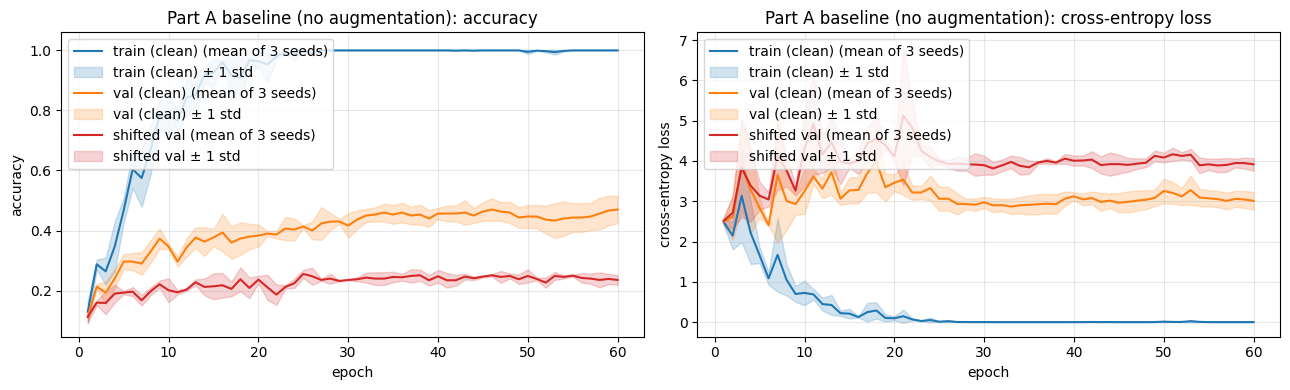

,metric,mean ± std (%)
0,train accuracy,100.0 ± 0.0
1,validation accuracy,47.0 ± 4.5
2,clean-test accuracy,43.1 ± 0.5
3,shifted-test accuracy,20.5 ± 0.3


In [ ]:
plot_curves(RESULTS["Part A baseline"]["hists"], "Part A baseline (no augmentation)")
summary_A = pd.DataFrame(
    {
        "metric": [
            "train accuracy",
            "validation accuracy",
            "clean-test accuracy",
            "shifted-test accuracy",
        ],
        "mean ± std (%)": [
            pm(df_base, c) for c in ["train_acc", "val_acc", "clean_test", "shifted_test"]
        ],
    }
)
summary_A

**Diagnosis:** 100% train accuracy vs 43.1% clean test means the model memorised the 400 images (overfitting).
The further drop to 20.5% on the shifted test is covariate shift (same labels, changed inputs), so the failure is both.

## Part B: Augmentation strategy
- Geometric (crop, horizontal flip, ±30° rotation, translate, scale) → targets the ±25° rotation.
- Photometric (colour jitter, grayscale, blur, noise) → targets brightness/contrast, blur and noise.
- Random Erasing → targets the ~25% occlusion.
- Mixup/CutMix + label smoothing → general regularisation.

**Vertical flip:** hurts, because CIFAR objects have a fixed "up" and the test only rotates by ±25°.

**±90° rotation vs ±25° test:** more robustness, but it wastes capacity on poses the test never has and lowers clean accuracy.

**Too much augmentation:** a small model under-fits (training accuracy drops), as Mixup/CutMix showed here.

## Part C: Regularisation and training design
- BatchNorm after every conv: stable training and less sensitivity to brightness.
- Dropout 0.3 only after Global Average Pooling: early conv features are spatially correlated, so dropout there barely regularises.
- Weight decay 5e-4 on weights only (not BatchNorm or biases).
- 3-epoch warm-up + cosine LR decay.
- Early stopping on robust validation (patience 20).
- Label smoothing 0.1 together with Mixup/CutMix.

Learning rate chosen from {0.02, 0.05, 0.1} using validation accuracy only.

In [ ]:
REG_CFG = dict(
    dropout=0.3,
    wd=0.0005,
    sched="cosine",
    ls=0.0,
    mix=False,
    select_best=True,
    patience=20,
    ema=None,
)
lr_rows = []
for lr in [0.02, 0.05, 0.1]:
    cfg = dict(REG_CFG, aug=["geo", "photo"], lr=lr)
    m, h, be = train_model(cfg, seed=0)
    lr_rows.append(
        {
            "lr": lr,
            "best_robust_val_acc": max(h["vrob_acc"]),
            "best_epoch": be,
            "robust_val_last5_mean": float(np.mean(h["vrob_acc"][-5:])),
            "clean_val_last5_mean": float(np.mean(h["val_acc"][-5:])),
        }
    )
    print(lr_rows[-1])
lr_df = pd.DataFrame(lr_rows)
BEST_LR = float(
    lr_df.sort_values(["robust_val_last5_mean", "best_robust_val_acc"], ascending=False).iloc[0][
        "lr"
    ]
)
print(f"selected learning rate (validation only): {BEST_LR}")
lr_df

{'lr': 0.02, 'best_robust_val_acc': 0.39, 'best_epoch': 33, 'robust_val_last5_mean': 0.36, 'clean_val_last5_mean': 0.44399999999999995}
{'lr': 0.05, 'best_robust_val_acc': 0.4125, 'best_epoch': 26, 'robust_val_last5_mean': 0.38049999999999995, 'clean_val_last5_mean': 0.454}
{'lr': 0.1, 'best_robust_val_acc': 0.3575, 'best_epoch': 44, 'robust_val_last5_mean': 0.3345, 'clean_val_last5_mean': 0.368}
selected learning rate (validation only): 0.05


,lr,best_robust_val_acc,best_epoch,robust_val_last5_mean,clean_val_last5_mean
0,0.02,0.3900,33,0.3600,0.444
1,0.05,0.4125,26,0.3805,0.454
2,0.10,0.3575,44,0.3345,0.368


## Part D: Ablation study

In [ ]:
ABLATION = {
    "No augmentation": dict(aug=[]),
    "Geometric only (crop, flip, rotation)": dict(aug=["geo"]),
    "Photometric only (color jitter, blur, noise)": dict(aug=["photo"]),
    "Geometric + photometric": dict(aug=["geo", "photo"]),
    "+ Cutout / Random Erasing": dict(aug=["geo", "photo", "erase"]),
    "+ Mixup or CutMix + label smoothing": dict(aug=["geo", "photo", "erase"], mix=True, ls=0.1),
}
ablation_dfs = {}
for name, over in ABLATION.items():
    cfg = dict(REG_CFG, lr=BEST_LR, **over)
    ablation_dfs[name] = run_config(name, cfg)

[No augmentation] 36s | train_acc 99.2±1.2 | val_acc 47.7±1.9 | val_shift_acc 27.0±3.1 | clean_test 40.7±2.1 | shifted_test 19.6±0.7
[Geometric only (crop, flip, rotation)] 83s | train_acc 88.7±9.6 | val_acc 44.7±1.9 | val_shift_acc 31.4±0.6 | clean_test 41.5±1.1 | shifted_test 21.7±0.3
[Photometric only (color jitter, blur, noise)] 110s | train_acc 89.1±14.9 | val_acc 44.7±1.9 | val_shift_acc 28.8±1.9 | clean_test 37.5±0.6 | shifted_test 21.0±0.7
[Geometric + photometric] 170s | train_acc 61.8±7.5 | val_acc 46.0±0.8 | val_shift_acc 38.2±1.4 | clean_test 40.5±1.9 | shifted_test 24.8±1.0
[+ Cutout / Random Erasing] 189s | train_acc 67.5±2.1 | val_acc 48.3±2.5 | val_shift_acc 41.3±3.4 | clean_test 42.9±2.0 | shifted_test 26.8±1.4
[+ Mixup or CutMix + label smoothing] 193s | train_acc 59.8±3.3 | val_acc 42.7±3.3 | val_shift_acc 37.6±1.9 | clean_test 40.8±0.4 | shifted_test 26.4±0.6


In [ ]:
best_aug_name = max(
    ablation_dfs,
    key=lambda n: (
        ablation_dfs[n]["val_robust_acc"].mean(),
        -ablation_dfs[n]["val_robust_acc"].std(),
    ),
)
print(
    pd.Series(
        {n: round(100 * d["val_robust_acc"].mean(), 2) for n, d in ablation_dfs.items()},
        name="robust val acc (%)",
    )
)
FINAL_CFG = dict(REG_CFG, lr=BEST_LR, **ABLATION[best_aug_name], ema=0.99)
print(f"best augmentation configuration by validation accuracy: {best_aug_name}")
print(f"final config: {FINAL_CFG}")
ablation_dfs["Final model"] = run_config("Final model", FINAL_CFG)

No augmentation                                 32.17
Geometric only (crop, flip, rotation)           34.75
Photometric only (color jitter, blur, noise)    32.75
Geometric + photometric                         40.17
+ Cutout / Random Erasing                       43.08
+ Mixup or CutMix + label smoothing             38.83
Name: robust val acc (%), dtype: float64
best augmentation configuration by validation accuracy: + Cutout / Random Erasing
final config: {'dropout': 0.3, 'wd': 0.0005, 'sched': 'cosine', 'ls': 0.0, 'mix': False, 'select_best': True, 'patience': 20, 'ema': 0.99, 'lr': 0.05, 'aug': ['geo', 'photo', 'erase']}
[Final model] 198s | train_acc 66.3±2.3 | val_acc 44.3±1.9 | val_shift_acc 38.2±3.0 | clean_test 43.1±1.5 | shifted_test 27.2±1.1


In [ ]:
rows = []
for name, df in ablation_dfs.items():
    rows.append(
        {
            "Configuration": name,
            "Val Acc (%)": pm(df, "val_acc"),
            "Shifted-Val Acc (%)": pm(df, "val_shift_acc"),
            "Clean Test (%)": pm(df, "clean_test"),
            "Shifted Test (%)": pm(df, "shifted_test"),
            "Train Acc (%)": pm(df, "train_acc"),
            "best epoch (per seed)": list(df["best_epoch"]),
        }
    )
ablation_table = pd.DataFrame(rows)
ablation_table.to_csv("results/ablation_table.csv", index=False)
ablation_table

,Configuration,Val Acc (%),Shifted-Val Acc (%),Clean Test (%),Shifted Test (%),Train Acc (%),best epoch (per seed)
0,No augmentation,47.7 ± 1.9,27.0 ± 3.1,40.7 ± 2.1,19.6 ± 0.7,99.2 ± 1.2,"[28, 41, 19]"
1,"Geometric only (crop, flip, rotation)",44.7 ± 1.9,31.4 ± 0.6,41.5 ± 1.1,21.7 ± 0.3,88.7 ± 9.6,"[23, 32, 45]"
2,"Photometric only (color jitter, blur, noise)",44.7 ± 1.9,28.8 ± 1.9,37.5 ± 0.6,21.0 ± 0.7,89.1 ± 14.9,"[30, 18, 47]"
3,Geometric + photometric,46.0 ± 0.8,38.2 ± 1.4,40.5 ± 1.9,24.8 ± 1.0,61.8 ± 7.5,"[26, 43, 55]"
4,+ Cutout / Random Erasing,48.3 ± 2.5,41.3 ± 3.4,42.9 ± 2.0,26.8 ± 1.4,67.5 ± 2.1,"[51, 46, 58]"
5,+ Mixup or CutMix + label smoothing,42.7 ± 3.3,37.6 ± 1.9,40.8 ± 0.4,26.4 ± 0.6,59.8 ± 3.3,"[54, 46, 51]"
6,Final model,44.3 ± 1.9,38.2 ± 3.0,43.1 ± 1.5,27.2 ± 1.1,66.3 ± 2.3,"[60, 49, 60]"


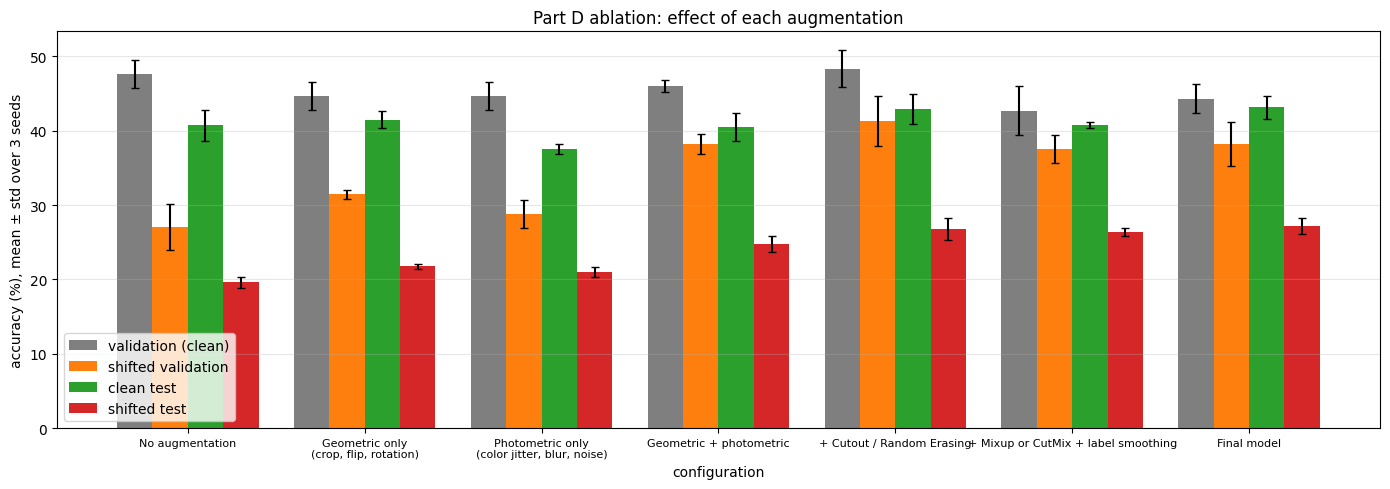

In [ ]:
names = list(ablation_dfs)
x = np.arange(len(names))
w = 0.2
fig, ax = plt.subplots(figsize=(14, 5))
for k, (col, lab, c) in enumerate(
    [
        ("val_acc", "validation (clean)", "tab:gray"),
        ("val_shift_acc", "shifted validation", "tab:orange"),
        ("clean_test", "clean test", "tab:green"),
        ("shifted_test", "shifted test", "tab:red"),
    ]
):
    means = [100 * ablation_dfs[n][col].mean() for n in names]
    stds = [100 * ablation_dfs[n][col].std(ddof=0) for n in names]
    ax.bar(x + (k - 1.5) * w, means, w, yerr=stds, capsize=3, label=lab, color=c)
ax.set_xticks(x)
ax.set_xticklabels([n.replace(" (", "\n(") for n in names], fontsize=8)
ax.set_xlabel("configuration")
ax.set_ylabel("accuracy (%), mean ± std over 3 seeds")
ax.set_title("Part D ablation: effect of each augmentation")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

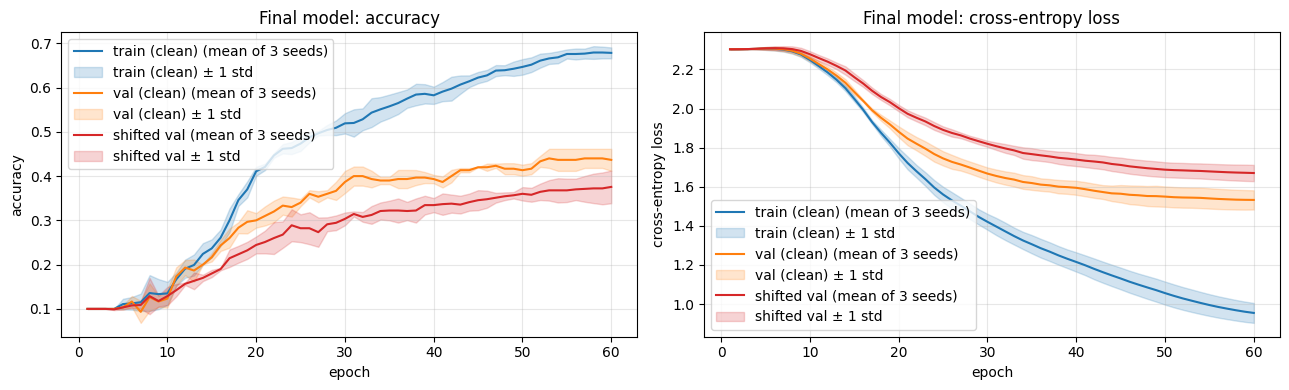

In [ ]:
plot_curves(RESULTS["Final model"]["hists"], "Final model")

In [ ]:
G = "Geometric only (crop, flip, rotation)"
P = "Photometric only (color jitter, blur, noise)"
GP = "Geometric + photometric"
CO = "+ Cutout / Random Erasing"
MX = "+ Mixup or CutMix + label smoothing"
NA = "No augmentation"
steps = [
    (NA, G, "add geometric augmentation (alone)"),
    (NA, P, "add photometric augmentation (alone)"),
    (P, GP, "add geometric on top of photometric"),
    (G, GP, "add photometric on top of geometric"),
    (GP, CO, "add Cutout / Random Erasing"),
    (CO, MX, "add Mixup/CutMix + label smoothing"),
    (best_aug_name, "Final model", "add weight EMA (final model)"),
    (NA, "Final model", "total: no augmentation → final model"),
]
def _d(a, b, col):
    return 100 * (ablation_dfs[b][col].mean() - ablation_dfs[a][col].mean())
gains = pd.DataFrame(
    {
        "change": [s[2] for s in steps],
        "from": [s[0] for s in steps],
        "to": [s[1] for s in steps],
        "Δ shifted test (pp)": [_d(a, b, "shifted_test") for a, b, _ in steps],
        "Δ shifted val (pp)": [_d(a, b, "val_shift_acc") for a, b, _ in steps],
    }
)
gains.round(2)

,change,from,to,Δ shifted test (pp),Δ shifted val (pp)
0,add geometric augmentation (alone),No augmentation,"Geometric only (crop, flip, rotation)",2.10,4.44
1,add photometric augmentation (alone),No augmentation,"Photometric only (color jitter, blur, noise)",1.35,1.78
2,add geometric on top of photometric,"Photometric only (color jitter, blur, noise)",Geometric + photometric,3.77,9.44
3,add photometric on top of geometric,"Geometric only (crop, flip, rotation)",Geometric + photometric,3.02,6.78
4,add Cutout / Random Erasing,Geometric + photometric,+ Cutout / Random Erasing,2.05,3.11
5,add Mixup/CutMix + label smoothing,+ Cutout / Random Erasing,+ Mixup or CutMix + label smoothing,-0.42,-3.78
6,add weight EMA (final model),+ Cutout / Random Erasing,Final model,0.36,-3.11
7,total: no augmentation → final model,No augmentation,Final model,7.53,11.22


**Largest gain:** adding geometric on top of photometric augmentation (+3.8 pp), because it matches the ±25° rotation.
Random Erasing added +2.0 pp because it matches the occlusion; Mixup/CutMix slightly hurt (−0.4 pp).

## Part E: Error analysis
### E.1 Per-class accuracy and confusion matrix

In [ ]:
def load_models(name):
    ms = []
    for s in SEEDS:
        m = MiniInceptionNet(dropout=RESULTS[name]["cfg"]["dropout"]).to(DEVICE)
        m.load_state_dict(torch.load(f"checkpoints/{slug(name)}_seed{s}.pt", map_location=DEVICE))
        m.eval()
        ms.append(m)
    return ms
final_models = load_models("Final model")
probs_shift = [predict_probs(m, x_shift) for m in final_models]
probs_clean = [predict_probs(m, x_clean_test) for m in final_models]
per_class = pd.DataFrame(
    {
        "class": CLASSES,
        "clean acc (%)": [
            f"{100 * np.mean([(p.argmax(1)[y_clean_test == c] == c).mean() for p in probs_clean]):.1f} ± {100 * np.std([(p.argmax(1)[y_clean_test == c] == c).mean() for p in probs_clean]):.1f}"
            for c in range(10)
        ],
        "shifted acc (%)": [
            f"{100 * np.mean([(p.argmax(1)[y_shift == c] == c).mean() for p in probs_shift]):.1f} ± {100 * np.std([(p.argmax(1)[y_shift == c] == c).mean() for p in probs_shift]):.1f}"
            for c in range(10)
        ],
    }
)
per_class

,class,clean acc (%),shifted acc (%)
0,airplane,40.8 ± 2.6,35.2 ± 3.3
1,automobile,59.3 ± 1.6,37.6 ± 2.1
2,bird,21.1 ± 1.1,21.1 ± 3.2
3,cat,29.2 ± 2.7,29.8 ± 2.1
4,deer,26.0 ± 2.4,17.0 ± 1.1
5,dog,25.9 ± 6.5,14.7 ± 3.0
6,frog,53.8 ± 5.0,17.8 ± 0.1
7,horse,63.8 ± 2.5,25.4 ± 0.5
8,ship,60.3 ± 4.8,45.4 ± 0.5
9,truck,50.9 ± 3.4,27.7 ± 2.0


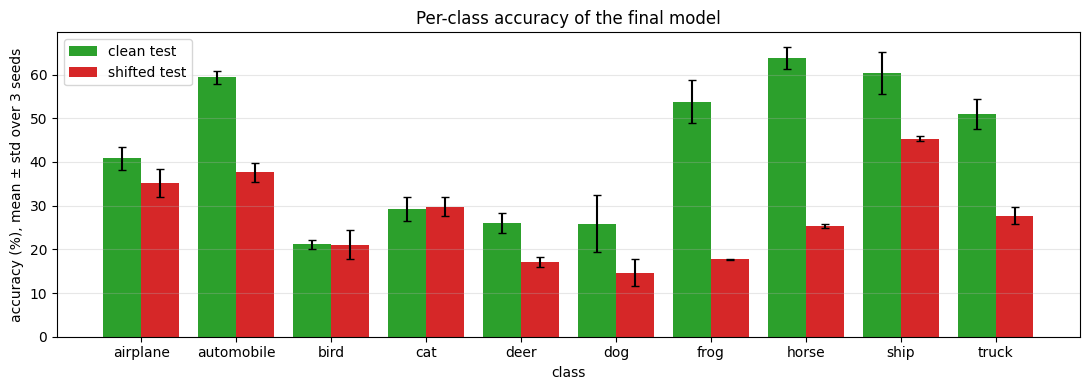

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
for k, (PR, Y, lab, c) in enumerate(
    [
        (probs_clean, y_clean_test, "clean test", "tab:green"),
        (probs_shift, y_shift, "shifted test", "tab:red"),
    ]
):
    accs = np.array([[(p.argmax(1)[Y == ci] == ci).mean() for ci in range(10)] for p in PR]) * 100
    ax.bar(
        np.arange(10) + (k - 0.5) * 0.4,
        accs.mean(0),
        0.4,
        yerr=accs.std(0),
        capsize=3,
        label=lab,
        color=c,
    )
ax.set_xticks(range(10))
ax.set_xticklabels(CLASSES)
ax.set_xlabel("class")
ax.set_ylabel("accuracy (%), mean ± std over 3 seeds")
ax.set_title("Per-class accuracy of the final model")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

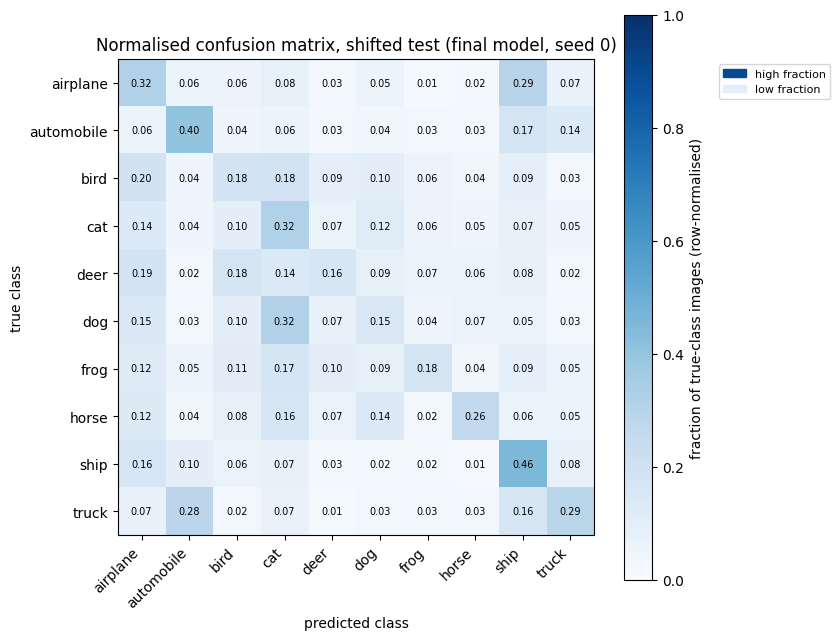

,fraction of true class,true,predicted as
0,0.317,dog,cat
1,0.293,airplane,ship
2,0.282,truck,automobile
3,0.195,bird,airplane
4,0.187,deer,airplane
5,0.184,bird,cat
6,0.179,deer,bird
7,0.172,automobile,ship


In [ ]:
pred_shift = probs_shift[0].argmax(1)
cm = confusion_matrix(y_shift, pred_shift, normalize="true")
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        ax.text(
            j,
            i,
            f"{cm[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7,
            color="white" if cm[i, j] > 0.5 else "black",
        )
ax.set_xticks(range(10))
ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticks(range(10))
ax.set_yticklabels(CLASSES)
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.set_title(f"Normalised confusion matrix, shifted test (final model, seed {SEEDS[0]})")
cb = plt.colorbar(im, ax=ax)
cb.set_label("fraction of true-class images (row-normalised)")
ax.legend(
    handles=[
        Patch(color=plt.cm.Blues(0.9), label="high fraction"),
        Patch(color=plt.cm.Blues(0.1), label="low fraction"),
    ],
    loc="upper left",
    bbox_to_anchor=(1.25, 1.0),
    fontsize=8,
)
plt.tight_layout()
plt.show()
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = sorted(
    [(off[i, j], CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if i != j],
    reverse=True,
)[:8]
pd.DataFrame(pairs, columns=["fraction of true class", "true", "predicted as"]).round(3)

**Most confused:** dog → cat, airplane → ship and truck → automobile, which share shape and background at 32×32.

### E.2 Misclassified images

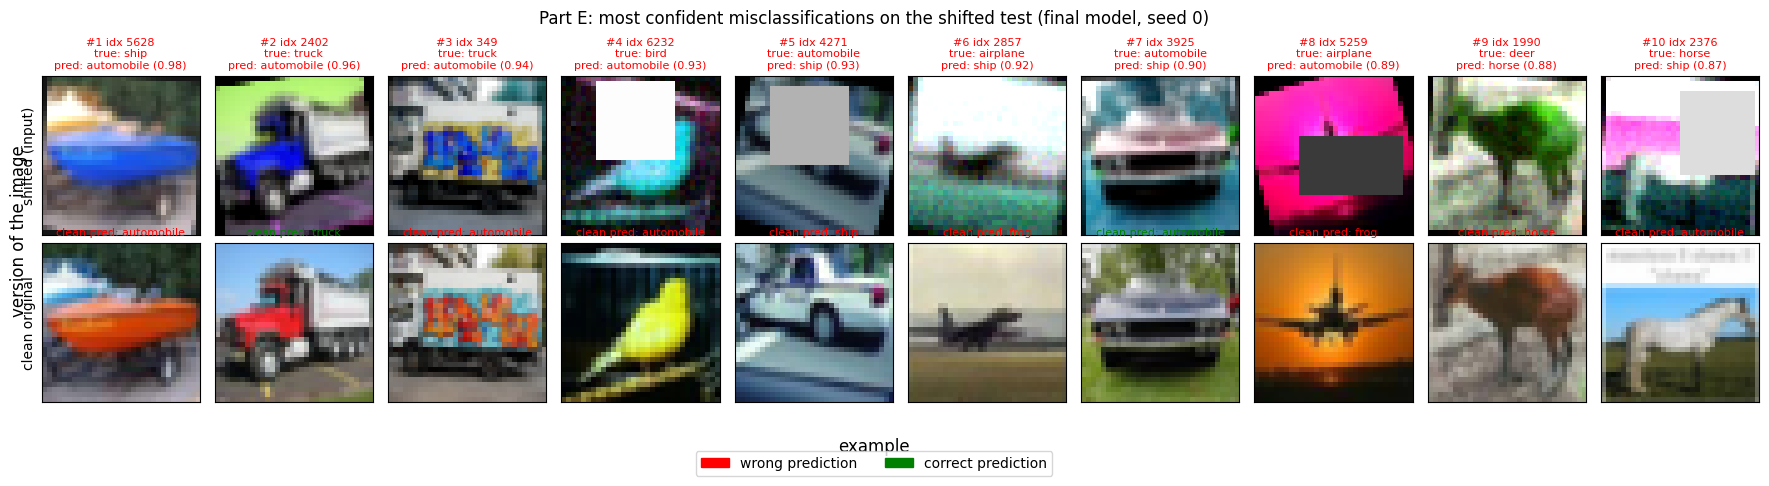

,#,index,true,pred (shifted),confidence,pred (clean),hidden corruption applied
0,1,5628,ship,automobile,0.982,automobile,True
1,2,2402,truck,automobile,0.964,truck,True
2,3,349,truck,automobile,0.938,automobile,True
3,4,6232,bird,automobile,0.929,automobile,True
4,5,4271,automobile,ship,0.926,ship,False
5,6,2857,airplane,ship,0.925,frog,True
6,7,3925,automobile,ship,0.902,automobile,True
7,8,5259,airplane,automobile,0.892,frog,True
8,9,1990,deer,horse,0.875,horse,True
9,10,2376,horse,ship,0.874,automobile,True


In [ ]:
p0 = probs_shift[0]
wrong = np.where(pred_shift != y_shift)[0]
conf_wrong = wrong[np.argsort(-p0[wrong].max(1))]
chosen = []
per_cls = {}
for i in conf_wrong:
    if per_cls.get(y_shift[i], 0) < 2:
        chosen.append(i)
        per_cls[y_shift[i]] = per_cls.get(y_shift[i], 0) + 1
    if len(chosen) == 10:
        break
clean_pred = probs_clean[0].argmax(1)
fig, axes = plt.subplots(2, 10, figsize=(18, 4.6))
for k, i in enumerate(chosen):
    axes[0, k].imshow(x_shift[i])
    axes[1, k].imshow(x_clean_test[i])
    axes[0, k].set_title(
        f"#{k + 1} idx {i}\ntrue: {CLASSES[y_shift[i]]}\npred: {CLASSES[pred_shift[i]]} ({p0[i].max():.2f})",
        fontsize=8,
        color="red",
    )
    axes[1, k].set_title(
        f"clean pred: {CLASSES[clean_pred[i]]}",
        fontsize=8,
        color="green" if clean_pred[i] == y_clean_test[i] else "red",
    )
    for r in range(2):
        axes[r, k].set_xticks([])
        axes[r, k].set_yticks([])
axes[0, 0].set_ylabel("shifted (input)")
axes[1, 0].set_ylabel("clean original")
fig.suptitle("Part E: most confident misclassifications on the shifted test (final model, seed 0)")
fig.supxlabel("example")
fig.supylabel("version of the image")
fig.legend(
    handles=[
        Patch(color="red", label="wrong prediction"),
        Patch(color="green", label="correct prediction"),
    ],
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.05),
)
plt.tight_layout()
plt.show()
mis_df = pd.DataFrame(
    {
        "#": range(1, len(chosen) + 1),
        "index": chosen,
        "true": [CLASSES[y_shift[i]] for i in chosen],
        "pred (shifted)": [CLASSES[pred_shift[i]] for i in chosen],
        "confidence": [round(float(p0[i].max()), 3) for i in chosen],
        "pred (clean)": [CLASSES[clean_pred[i]] for i in chosen],
        "hidden corruption applied": (
            [bool(shift_hidden_mask[i]) for i in chosen]
            if shift_hidden_mask is not None
            else ["unknown"] * len(chosen)
        ),
    }
)
mis_df

1. ship → automobile: channel swap turned the boat blue and the hull looks like a car body.
2. truck → automobile: channel swap and rotation leave only a car-like cab.
3. truck → automobile: noise and channel swap hide the box-truck texture.
4. bird → automobile: occlusion covers the bird and its colour changed.
5. automobile → ship: occlusion hides the cabin and the blue-grey background looks like water.
6. airplane → ship: heavy brightening hides the fuselage and the teal ground looks like water.
7. automobile → ship: channel swap turns grass blue, which reads as water.
8. airplane → automobile: sunset turned magenta and occlusion covers the body.
9. deer → horse: deer turned green and has the same body shape as a horse.
10. horse → ship: sky turned magenta and occlusion covers the horse.

### E.3 Hidden-corruption test (channel swap only)

In [ ]:
hidden_rows = []
for name in ["No augmentation", "Geometric + photometric", "Final model"]:
    accs_clean = [r["clean_test"] for r in RESULTS[name]["rows"]]
    accs_hidden = [evaluate(m, x_hidden, y_clean_test)[0] for m in load_models(name)]
    hidden_rows.append(
        {
            "model": name,
            "clean test (%)": f"{100 * np.mean(accs_clean):.1f} ± {100 * np.std(accs_clean):.1f}",
            "hidden-corruption only (%)": f"{100 * np.mean(accs_hidden):.1f} ± {100 * np.std(accs_hidden):.1f}",
            "drop (pp)": round(100 * (np.mean(accs_clean) - np.mean(accs_hidden)), 1),
        }
    )
hidden_df = pd.DataFrame(hidden_rows)
hidden_df

,model,clean test (%),hidden-corruption only (%),drop (pp)
0,No augmentation,40.7 ± 2.1,29.4 ± 0.3,11.3
1,Geometric + photometric,40.5 ± 1.9,24.5 ± 1.2,16.0
2,Final model,43.1 ± 1.5,24.3 ± 1.6,18.8


In [ ]:
if shift_hidden_mask is not None:
    split_rows = []
    for s, p in zip(SEEDS, probs_shift):
        ok = p.argmax(1) == y_shift
        split_rows.append(
            {
                "seed": s,
                "shifted, without hidden corruption": ok[~shift_hidden_mask].mean(),
                "shifted, with hidden corruption": ok[shift_hidden_mask].mean(),
            }
        )
    split_df = pd.DataFrame(split_rows)
    print({c: pm(split_df, c) for c in split_df.columns[1:]})
    display(split_df.round(4))

{'shifted, without hidden corruption': '34.8 ± 1.2', 'shifted, with hidden corruption': '19.4 ± 1.1'}


,seed,"shifted, without hidden corruption","shifted, with hidden corruption"
0,0,0.3509,0.1900
1,1,0.3313,0.1837
2,2,0.3606,0.2090


**Result:** the augmentation did not generalise: the final model drops 18.8 pp vs 11.3 pp without augmentation, because no augmentation permutes colour channels.

## Part F: Test-time augmentation (bonus)

In [ ]:
def tta_views(x):
    views = [x, torch.flip(x, dims=[3])]
    xp = F.pad(x, (2, 2, 2, 2), mode="reflect")
    for dy, dx in [(0, 2), (0, -2), (2, 0), (-2, 0)]:
        views.append(xp[:, :, 2 + dy : 34 + dy, 2 + dx : 34 + dx])
    xpf = torch.flip(xp, dims=[3])
    for dx in [2, -2]:
        views.append(xpf[:, :, 2:34, 2 + dx : 34 + dx])
    return views
@torch.no_grad()
def predict_tta(model, x_uint8, bs=500):
    model.eval()
    out = []
    for i in range(0, len(x_uint8), bs):
        xb = to_input(x_uint8[i : i + bs]).to(DEVICE)
        out.append(torch.stack([F.softmax(model(v), 1) for v in tta_views(xb)]).mean(0).cpu())
    return torch.cat(out).numpy()
tta_rows = []
for s, m in zip(SEEDS, final_models):
    t0 = time.time()
    p_plain = predict_probs(m, x_shift)
    t_plain = time.time() - t0
    t0 = time.time()
    p_tta = predict_tta(m, x_shift)
    t_tta = time.time() - t0
    tta_rows.append(
        {
            "seed": s,
            "shifted acc, no TTA": (p_plain.argmax(1) == y_shift).mean(),
            "shifted acc, TTA (N=8)": (p_tta.argmax(1) == y_shift).mean(),
            "time no TTA (s)": t_plain,
            "time TTA (s)": t_tta,
        }
    )
tta_df = pd.DataFrame(tta_rows)
print(f"shifted test without TTA: {pm(tta_df, 'shifted acc, no TTA')} %")
print(f"shifted test with TTA   : {pm(tta_df, 'shifted acc, TTA (N=8)')} %")
print(
    f"change: {100 * (tta_df['shifted acc, TTA (N=8)'] - tta_df['shifted acc, no TTA']).mean():+.2f} pp"
)
print(
    f"inference time for 10,000 images: {tta_df['time no TTA (s)'].mean():.2f}s -> {tta_df['time TTA (s)'].mean():.2f}s ({tta_df['time TTA (s)'].mean() / tta_df['time no TTA (s)'].mean():.1f}× cost) on {DEVICE}"
)
tta_df.round(4)

shifted test without TTA: 27.2 ± 1.1 %
shifted test with TTA   : 27.4 ± 1.1 %
change: +0.29 pp
inference time for 10,000 images: 0.50s -> 3.83s (7.7× cost) on cuda


,seed,"shifted acc, no TTA","shifted acc, TTA (N=8)",time no TTA (s),time TTA (s)
0,0,0.2712,0.2736,0.4932,3.7875
1,1,0.2582,0.2611,0.5037,3.8123
2,2,0.2855,0.2888,0.5030,3.9032


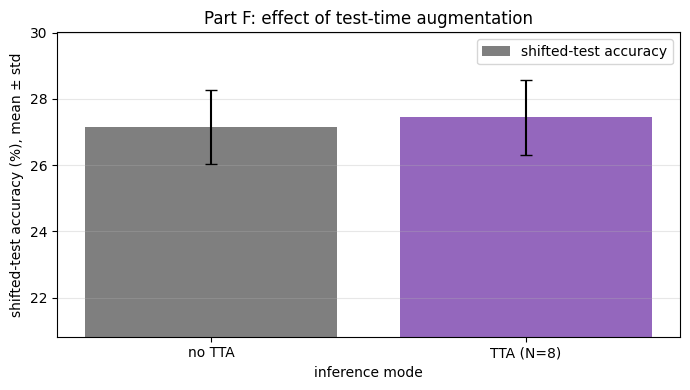

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    ["no TTA", "TTA (N=8)"],
    [100 * tta_df["shifted acc, no TTA"].mean(), 100 * tta_df["shifted acc, TTA (N=8)"].mean()],
    yerr=[
        100 * tta_df["shifted acc, no TTA"].std(ddof=0),
        100 * tta_df["shifted acc, TTA (N=8)"].std(ddof=0),
    ],
    capsize=4,
    color=["tab:gray", "tab:purple"],
    label="shifted-test accuracy",
)
ax.set_ylabel("shifted-test accuracy (%), mean ± std")
ax.set_xlabel("inference mode")
ax.set_title("Part F: effect of test-time augmentation")
ax.legend()
ax.grid(axis="y", alpha=0.3)
lo = 100 * min(tta_df["shifted acc, no TTA"].min(), tta_df["shifted acc, TTA (N=8)"].min())
ax.set_ylim(max(0, lo - 5), None)
plt.tight_layout()
plt.show()

**Result:** +0.29 pp shifted-test accuracy at 7.7× inference cost.

## Final summary

In [ ]:
fin = ablation_dfs["Final model"]
print("FINAL TEST SCORE (shifted test, mean ± std over seeds 0,1,2):", pm(fin, "shifted_test"), "%")
print(
    "clean test:",
    pm(fin, "clean_test"),
    "% | validation (clean):",
    pm(fin, "val_acc"),
    "% | shifted validation:",
    pm(fin, "val_shift_acc"),
    "%",
)
print("with TTA (bonus):", pm(tta_df, "shifted acc, TTA (N=8)"), "%")
print("configuration:", FINAL_CFG)
print(
    f"model: MiniInceptionNet, {N_PARAMS:,} trainable parameters, trained from scratch, max {MAX_EPOCHS} epochs, batch {BATCH_SIZE}"
)
single = gains[~gains["change"].str.startswith("total")]
big = single.loc[single["Δ shifted test (pp)"].idxmax()]
print(f"largest single gain: {big['change']}  ({big['Δ shifted test (pp)']:+.1f} pp shifted test)")

FINAL TEST SCORE (shifted test, mean ± std over seeds 0,1,2): 27.2 ± 1.1 %
clean test: 43.1 ± 1.5 % | validation (clean): 44.3 ± 1.9 % | shifted validation: 38.2 ± 3.0 %
with TTA (bonus): 27.4 ± 1.1 %
configuration: {'dropout': 0.3, 'wd': 0.0005, 'sched': 'cosine', 'ls': 0.0, 'mix': False, 'select_best': True, 'patience': 20, 'ema': 0.99, 'lr': 0.05, 'aug': ['geo', 'photo', 'erase']}
model: MiniInceptionNet, 567,018 trainable parameters, trained from scratch, max 60 epochs, batch 32
largest single gain: add geometric on top of photometric  (+3.8 pp shifted test)
